In [1]:
import os
import matplotlib.pyplot as plt
from IPython.display import clear_output
import random


import numpy as np
from torchgeo.models import ResNet18_Weights
import rasterio
import timm

In [5]:
'''This set of weights is a torchvision WeightEnum 
and holds information such as the download url link or additional meta data. 
TorchGeo takes care of the downloading and initialization of models with a desired set of weights. 
Given that EuroSAT is a classification dataset, 
we can use a ClassificationTask object that holds the model and optimizer object 
as well as the training logic.


'''
weights = ResNet18_Weights.SENTINEL2_ALL_MOCO

In [14]:
dir(ResNet18_Weights.SENTINEL2_ALL_MOCO)

['LANDSAT_ETM_SR_MOCO',
 'LANDSAT_ETM_SR_SIMCLR',
 'LANDSAT_ETM_TOA_MOCO',
 'LANDSAT_ETM_TOA_SIMCLR',
 'LANDSAT_OLI_SR_MOCO',
 'LANDSAT_OLI_SR_SIMCLR',
 'LANDSAT_OLI_TIRS_TOA_MOCO',
 'LANDSAT_OLI_TIRS_TOA_SIMCLR',
 'LANDSAT_TM_TOA_MOCO',
 'LANDSAT_TM_TOA_SIMCLR',
 'SENTINEL2_ALL_MOCO',
 'SENTINEL2_RGB_MOCO',
 'SENTINEL2_RGB_SECO',
 '__class__',
 '__doc__',
 '__eq__',
 '__hash__',
 '__module__',
 'get_state_dict',
 'meta',
 'name',
 'transforms',
 'url',
 'value',
 'verify']

In [19]:
ResNet18_Weights.SENTINEL2_RGB_SECO.transforms

AugmentationSequential(
  (augs): AugmentationSequential(
    (Resize_0): Resize(output_size=256, p=1.0, p_batch=1.0, same_on_batch=True, size=256, side=short, resample=bilinear, align_corners=True, antialias=False)
    (CenterCrop_1): CenterCrop(p=1.0, p_batch=1.0, same_on_batch=True, resample=bilinear, cropping_mode=slice, align_corners=True, size=(224, 224), padding_mode=zeros)
    (Normalize_2): Normalize(p=1.0, p_batch=1.0, same_on_batch=True, mean=tensor([3, 2, 0]), std=tensor([ 85, 101, 129]))
    (Normalize_3): Normalize(p=1.0, p_batch=1.0, same_on_batch=True, mean=0, std=0.003921568859368563)
    (Normalize_4): Normalize(p=1.0, p_batch=1.0, same_on_batch=True, mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
  )
)

In [3]:
weights

ResNet18_Weights.SENTINEL2_ALL_MOCO

In [12]:
in_chans = weights.meta["in_chans"]
model = timm.create_model("resnet18", in_chans=in_chans, num_classes=10)

In [13]:
model.load_state_dict(weights.get_state_dict(progress=True), strict=False)

Downloading: "https://hf.co/torchgeo/resnet18_sentinel2_all_moco/resolve/5b8cddc9a14f3844350b7f40b85bcd32aed75918/resnet18_sentinel2_all_moco-59bfdff9.pth" to /home/jan/.cache/torch/hub/checkpoints/resnet18_sentinel2_all_moco-59bfdff9.pth
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 42.8M/42.8M [00:00<00:00, 83.1MB/s]


_IncompatibleKeys(missing_keys=['fc.weight', 'fc.bias'], unexpected_keys=[])

In [14]:
import sys
sys.path.append('../')

In [22]:
from model.model_blocks import *

In [32]:
import torchvision.models as models

net = ModifiedResNet18(models.resnet.BasicBlock, [2, 2, 2, 2], apply_after_layer=3)



In [33]:
net.conv1 = nn.Conv2d(4, 
                    net.conv1.out_channels, 
                    kernel_size=net.conv1.kernel_size, 
                    stride=net.conv1.stride, 
                    padding=net.conv1.padding,
                    bias=False) 

In [37]:
net.load_state_dict(state_dict, strict=False)

_IncompatibleKeys(missing_keys=['fc.weight', 'fc.bias'], unexpected_keys=[])

In [4]:
from rasterio.plot import show


In [4]:
def plot_images(data):
    
    n_images = data.shape[0]
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :]
        img = img/0.25

        ax[idx].imshow(img.transpose(1, 2, 0)[:,:,[2,1,0]])
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()

In [5]:
sampleid = '110000091'
sampleid = '30000043'
dataset = 'four_images'
#dataset = 'SR_four_images'


for file in os.listdir(os.path.join(folder, sampleid)):
    print(file)

20220105T105339_20220105T110526_T29NPJ_opaque_clouds_0_cirrus_0_CLOUD_PERC_0.tif
20220619T104631_20220619T105906_T29NPJ_opaque_clouds_0_cirrus_0_CLOUD_PERC_22.33.tif
20220818T104631_20220818T105820_T29NPJ_opaque_clouds_0_cirrus_0_CLOUD_PERC_28.37.tif
20221226T105451_20221226T105746_T29NPJ_opaque_clouds_0_cirrus_0_CLOUD_PERC_0.tif


['10623783']

In [47]:


#dataset = 'SR_four_images'
#dataset = 'four_images'

data = []
for file in os.listdir(os.path.join(folder, sampleid)):
    with rasterio.open(os.path.join(folder, sampleid, file)) as src:
        img_data = src.read()
        #show(src)
        data.append(img_data)
        
data = np.array(data)

In [48]:
data.shape

(4, 5, 120, 120)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


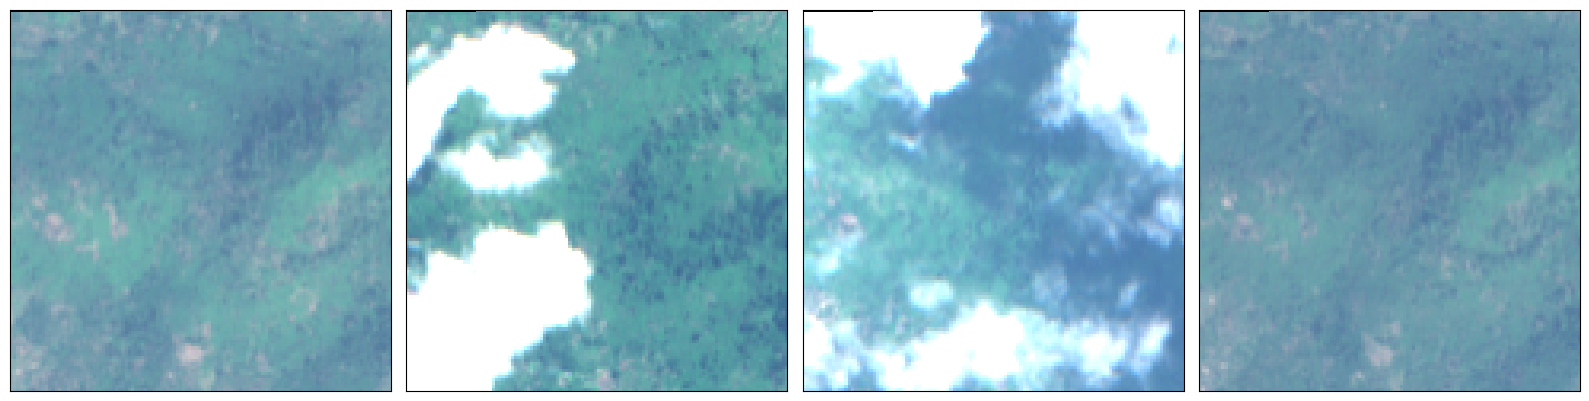

In [49]:
plot_images(data/data.max())

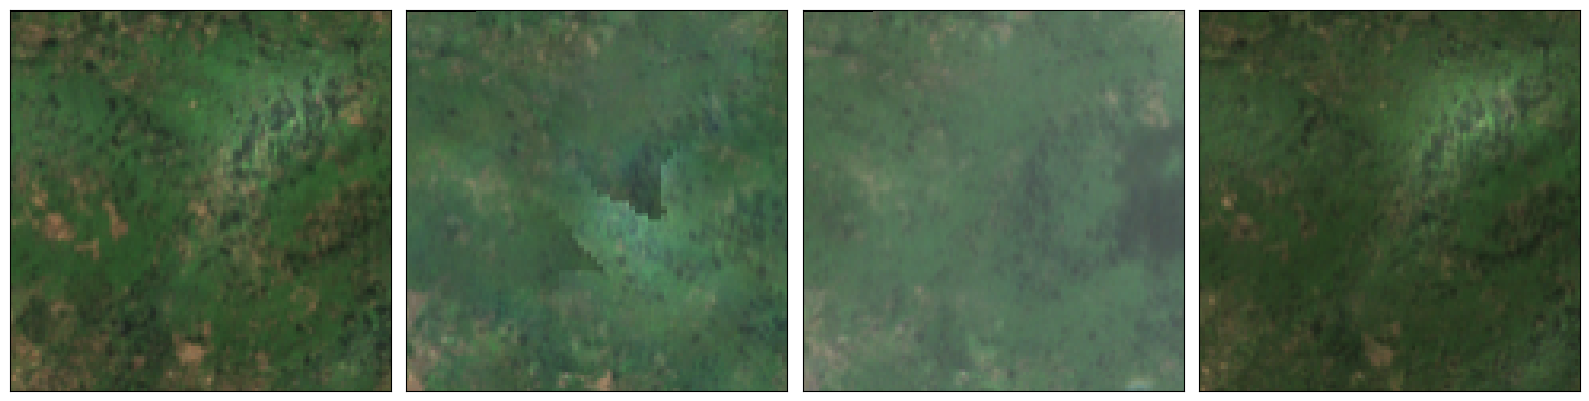

In [44]:
plot_images(data/data.max())

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


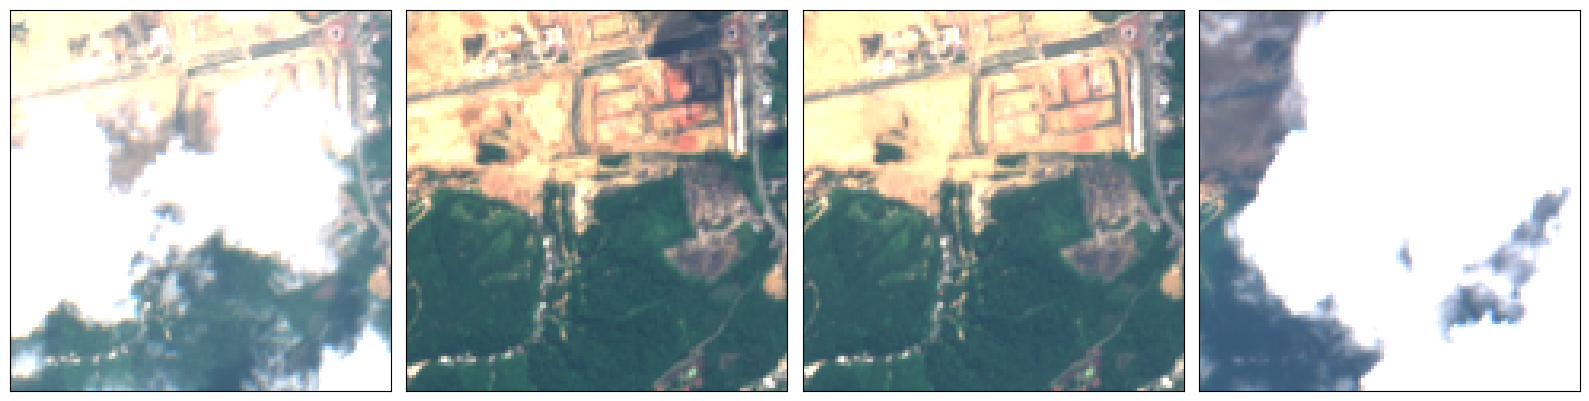

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


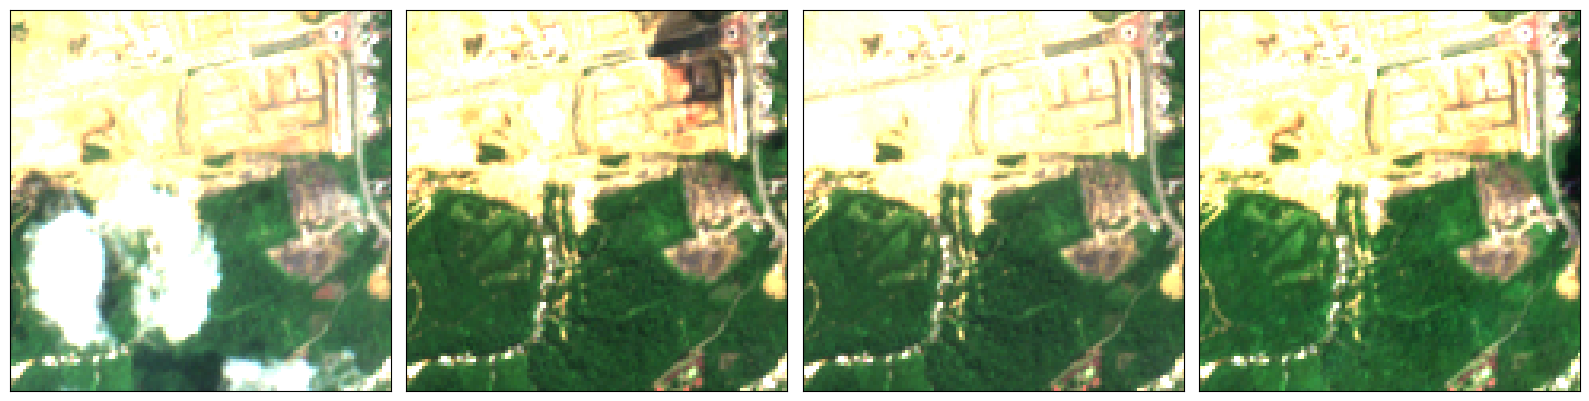

KeyboardInterrupt: Interrupted by user

In [6]:
sampleids = os.listdir(f'/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/SR_four_images/')




while True:

    sampleid = random.sample(sampleids, 1)[0]
    
    for dataset in ['four_images', 'SR_four_images']:
        folder = f'/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/{dataset}/'

        data = []
        for file in os.listdir(os.path.join(folder, sampleid)):
            with rasterio.open(os.path.join(folder, sampleid, file)) as src:
                img_data = src.read()
                #show(src)
                data.append(img_data)
        
        data = np.array(data)
        plot_images(data/data.max())
    
    '''folder = f'/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/SR_one_image/'
    with rasterio.open(os.path.join(folder, sampleid, os.listdir(os.path.join(folder, sampleid))[0])) as src:
        img = src.read() 
        img = img/img.max()
        img = img/0.25
        img = img.transpose(1, 2, 0)[:,:,[2,1,0]]
        plt.imshow(img)
        plt.show()'''

    _waitforinput = input()

    clear_output(wait=True)

    